In [58]:
import os
import sys
import json
import random
import warnings
from pathlib import Path

# Resolve the checkout from either the project root or research/notebooks.
PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "run.py").is_file() and (p / "backend").is_dir()
)


import numpy as np
import pandas as pd

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from sqlalchemy import create_engine, text

warnings.filterwarnings("ignore")

In [59]:
import sys
print(sys.executable)

import torch
import numpy
import einops

print("torch:", torch.__version__)
print("numpy:", numpy.__version__)
print("einops:", einops.__version__)

/opt/homebrew/opt/python@3.12/bin/python3.12
torch: 2.10.0
numpy: 2.0.2
einops: 0.8.1


In [ ]:

# Dossier local où tu as copié les fichiers SAINT du repo
SAINT_LOCAL_DIR = PROJECT_ROOT / "research/saint"

# Export
OUTPUT_DIR = PROJECT_ROOT / "artifacts/embeddings/saint"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Base PostgreSQL
DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = int(os.getenv("DB_PORT", "5432"))
DB_USER = os.getenv("DB_USER", "postgres")
DB_PASSWORD = os.getenv("DB_PASSWORD", "")
DB_NAME = os.getenv("DB_NAME", "DAE-PFAS")

#  données
CATEGORY_FILTER = "Measurement"   
SQL_LIMIT = None                 
DROP_ALL_ZERO_ROWS = False
CLIP_NEGATIVE_TO_ZERO = True

# Preprocessing
USE_LOG1P = True
USE_STANDARDIZE = True

# SAINT 
RANDOM_SEED = 42
BATCH_SIZE = 256
EMBEDDING_SIZE = 8
TRANSFORMER_DEPTH = 1
ATTENTION_HEADS = 4
ATTENTION_DROPOUT = 0.1
FF_DROPOUT = 0.1
LEARNING_RATE = 1e-4
PRETRAIN_EPOCHS = 10

# Prétraining
USE_CONTRASTIVE = True
USE_DENOISING = True
CUTMIX_LAMBDA = 0.10
NCE_TEMP = 0.7
LAM_CONTRASTIVE = 0.5
LAM_DENOISE_CONT = 1.0

# Extraction embeddings
POOLING = "mean"   # "mean" 

# Test rapide clustering
RUN_KMEANS_TEST = True
KMEANS_K = 5

In [61]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [62]:
required_paths = [
    SAINT_LOCAL_DIR / "augmentations.py",
    SAINT_LOCAL_DIR / "models" / "__init__.py",
    SAINT_LOCAL_DIR / "models" / "model.py",
    SAINT_LOCAL_DIR / "models" / "pretrainmodel.py",
]

missing = [str(p) for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Fichiers SAINT manquants.\n"
        + "\n".join(missing)
        + "\n\nCrée le dossier saint_local/ avec les fichiers copiés du repo."
    )

if str(SAINT_LOCAL_DIR) not in sys.path:
    sys.path.insert(0, str(SAINT_LOCAL_DIR))

from models.pretrainmodel import SAINT
from augmentations import embed_data_mask, add_noise

print("Imports SAINT OK")

Imports SAINT OK


In [63]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv(PROJECT_ROOT / ".local/project.env")

PG_PARAMS = {
    "host": os.getenv("DB_HOST", "localhost"),
    "port": int(os.getenv("DB_PORT", "5432")),
    "user": os.getenv("DB_USER", "postgres"),
    "password": os.getenv("DB_PASSWORD", ""),
    "dbname": os.getenv("DB_NAME", "DAE-PFAS"),
}

engine = create_engine(
    "postgresql+pg8000://",
    connect_args={
        "host": PG_PARAMS["host"],
        "port": PG_PARAMS["port"],
        "user": PG_PARAMS["user"],
        "password": PG_PARAMS["password"],
        "database": PG_PARAMS["dbname"],
    },
    pool_pre_ping=True,
)

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Connexion PostgreSQL OK")
print(PG_PARAMS)

Connexion PostgreSQL OK
{'host': 'localhost', 'port': 5432, 'user': 'postgres', 'password': '', 'dbname': 'DAE-PFAS'}


In [64]:
def get_point_pfas_columns(engine) -> list[str]:
    query = text("""
        SELECT column_name
        FROM information_schema.columns
        WHERE table_schema = 'public'
          AND table_name = 'point'
          AND column_name ILIKE 'pfas_%'
        ORDER BY ordinal_position
    """)

    with engine.connect() as conn:
        rows = conn.execute(query).fetchall()

    cols = []
    for row in rows:
        col = row[0]
        if col.startswith("pfas_"):
            suffix = col.split("_", 1)[1]
            if suffix.isdigit():
                cols.append(col)

    cols = sorted(cols, key=lambda c: int(c.split("_")[1]))
    return cols


def load_pfas_dataframe(engine, category_filter=None, sql_limit=None) -> pd.DataFrame:
    pfas_cols = get_point_pfas_columns(engine)
    if not pfas_cols:
        raise RuntimeError("Aucune colonne PFAS trouvée dans public.point")

    pfas_sql = ", ".join([f'v."{col}"' for col in pfas_cols])

    where_clauses = ["p.lat IS NOT NULL", "p.lon IS NOT NULL"]
    params = {}

    if category_filter is not None:
        where_clauses.append("p.category = :category_filter")
        params["category_filter"] = category_filter

    where_sql = ""
    if where_clauses:
        where_sql = "WHERE " + " AND ".join(where_clauses)

    limit_sql = ""
    if sql_limit is not None:
        limit_sql = "LIMIT :sql_limit"
        params["sql_limit"] = int(sql_limit)

    query = text(f"""
        SELECT
            p.id AS point_id,
            p.lat,
            p.lon,
            p.year,
            p.category,
            p.matrix,
            p.dataset_id,
            p.pfas_sum,
            {pfas_sql}
        FROM public.pfas_points p
        JOIN public.point v
          ON v.point_id = p.id
        {where_sql}
        ORDER BY p.id
        {limit_sql}
    """)

    df = pd.read_sql(query, engine, params=params)

    if df.empty:
        raise RuntimeError("La jointure pfas_points + point est vide.")

    df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
    df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
    df["pfas_sum"] = pd.to_numeric(df["pfas_sum"], errors="coerce").fillna(0.0)

    if "year" in df.columns:
        df["year"] = pd.to_numeric(df["year"], errors="coerce")

    if "dataset_id" in df.columns:
        df["dataset_id"] = df["dataset_id"].astype(str)

    if "matrix" in df.columns:
        df["matrix"] = df["matrix"].astype(str)

    if "category" in df.columns:
        df["category"] = df["category"].astype(str)

    for col in df.columns:
        if col.startswith("pfas_"):
            df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.dropna(subset=["lat", "lon"]).copy()
    return df

In [65]:
df_raw = load_pfas_dataframe(
    engine=engine,
    category_filter=CATEGORY_FILTER,
    sql_limit=SQL_LIMIT,
)

print("Shape brute :", df_raw.shape)
display(df_raw.head())

Shape brute : (87281, 555)


,point_id,lat,lon,year,category,matrix,dataset_id,pfas_sum,pfas_1,pfas_2,...,pfas_538,pfas_539,pfas_540,pfas_541,pfas_542,pfas_543,pfas_544,pfas_545,pfas_546,pfas_547
0,12622,50.808932,3.352552,2018.0,Measurement,Surface water,10,130.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,12623,51.016507,4.088303,2017.0,Measurement,Surface water,10,200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12624,51.042282,3.548967,2016.0,Measurement,Surface water,10,42400.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,12625,51.771554,6.605953,2017.0,Measurement,Surface water,10,50.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,12626,49.590101,7.603395,2018.0,Measurement,Surface water,10,580.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [66]:
pfas_cols = [c for c in df_raw.columns if c.startswith("pfas_")]
if "point_id" not in df_raw.columns:
    raise RuntimeError("La colonne point_id est absente")

df = df_raw[["point_id", *pfas_cols]].copy()

print("Nb PFAS colonnes :", len(pfas_cols))
print("Shape sélectionnée :", df.shape)

Nb PFAS colonnes : 548
Shape sélectionnée : (87281, 549)


In [ ]:
# Conversion numérique
for col in pfas_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

#  inf -> NaN
df[pfas_cols] = df[pfas_cols].replace([np.inf, -np.inf], np.nan)

# Fill NaN par 0
df[pfas_cols] = df[pfas_cols].fillna(0.0)

#  clip négatifs à 0
if CLIP_NEGATIVE_TO_ZERO:
    df[pfas_cols] = df[pfas_cols].clip(lower=0.0)

# supprimer les lignes totalement nulles
if DROP_ALL_ZERO_ROWS:
    row_sum = df[pfas_cols].sum(axis=1)
    df = df.loc[row_sum > 0].copy()

# Supprimer les colonnes constantes / nulles
stds = df[pfas_cols].std(axis=0)
kept_pfas_cols = stds[stds > 0].index.tolist()

df = df[["point_id", *kept_pfas_cols]].copy()
pfas_cols = kept_pfas_cols

print("Après nettoyage :", df.shape)
print("Nb colonnes PFAS gardées :", len(pfas_cols))

Après nettoyage : (87281, 291)
Nb colonnes PFAS gardées : 290


In [68]:
point_ids = df["point_id"].astype(np.int64).to_numpy()
X_raw = df[pfas_cols].to_numpy(dtype=np.float32)

preprocess_info = {
    "clip_negative_to_zero": CLIP_NEGATIVE_TO_ZERO,
    "drop_all_zero_rows": DROP_ALL_ZERO_ROWS,
    "use_log1p": USE_LOG1P,
    "use_standardize": USE_STANDARDIZE,
    "n_rows": int(X_raw.shape[0]),
    "n_features": int(X_raw.shape[1]),
}

X_proc = X_raw.copy()

if USE_LOG1P:
    X_proc = np.log1p(X_proc)

scaler = None
if USE_STANDARDIZE:
    scaler = StandardScaler()
    X_proc = scaler.fit_transform(X_proc).astype(np.float32)

print("X_raw shape :", X_raw.shape)
print("X_proc shape:", X_proc.shape)

X_raw shape : (87281, 290)
X_proc shape: (87281, 290)


In [69]:
class PfasSaintDataset(Dataset):
    def __init__(self, point_ids: np.ndarray, x_cont: np.ndarray):
        self.point_ids = point_ids.astype(np.int64)
        self.x_cont = x_cont.astype(np.float32)

        n = self.x_cont.shape[0]

        # Un seul token catégoriel artificiel = CLS
        self.x_categ = np.zeros((n, 1), dtype=np.int64)

        # Masques
        self.cat_mask = np.ones_like(self.x_categ, dtype=np.int64)
        self.con_mask = np.ones_like(self.x_cont, dtype=np.int64)

    def __len__(self):
        return len(self.point_ids)

    def __getitem__(self, idx):
        return (
            self.point_ids[idx],
            self.x_categ[idx],
            self.x_cont[idx],
            self.cat_mask[idx],
            self.con_mask[idx],
        )

dataset = PfasSaintDataset(point_ids=point_ids, x_cont=X_proc)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

print("Dataset OK :", len(dataset))

Dataset OK : 87281


In [70]:
num_continuous = X_proc.shape[1]

model = SAINT(
    categories=(1,),                 # seulement le token CLS
    num_continuous=num_continuous,   # toutes les concentrations PFAS
    dim=EMBEDDING_SIZE,
    depth=TRANSFORMER_DEPTH,
    heads=ATTENTION_HEADS,
    dim_head=16,
    dim_out=1,
    mlp_hidden_mults=(4, 2),
    num_special_tokens=0,
    attn_dropout=ATTENTION_DROPOUT,
    ff_dropout=FF_DROPOUT,
    cont_embeddings="MLP",
    attentiontype="col",             # version légère pour commencer
    final_mlp_style="sep",
    y_dim=2,
).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total trainable params:", total_params)

SAINT(
  (norm): LayerNorm((290,), eps=1e-05, elementwise_affine=True)
  (simple_MLP): ModuleList(
    (0-289): 290 x simple_MLP(
      (layers): Sequential(
        (0): Linear(in_features=1, out_features=100, bias=True)
        (1): ReLU()
        (2): Linear(in_features=100, out_features=8, bias=True)
      )
    )
  )
  (transformer): Transformer(
    (layers): ModuleList(
      (0): ModuleList(
        (0): PreNorm(
          (norm): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
          (fn): Residual(
            (fn): Attention(
              (to_qkv): Linear(in_features=8, out_features=192, bias=False)
              (to_out): Linear(in_features=64, out_features=8, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
          )
        )
        (1): PreNorm(
          (norm): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
          (fn): Residual(
            (fn): FeedForward(
              (net): Sequential(
                (0): Linear

In [71]:
def saint_pretrain(
    model,
    loader,
    device,
    epochs=10,
    lr=1e-4,
    use_contrastive=True,
    use_denoising=True,
    cutmix_lambda=0.10,
    nce_temp=0.7,
    lam_contrastive=0.5,
    lam_denoise_cont=1.0,
):
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    ce_loss = nn.CrossEntropyLoss()
    mse_loss = nn.MSELoss()

    history = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for batch in loader:
            _, x_categ, x_cont, cat_mask, con_mask = batch

            x_categ = x_categ.to(device)
            x_cont = x_cont.to(device)
            cat_mask = cat_mask.to(device)
            con_mask = con_mask.to(device)

            optimizer.zero_grad()
            loss = 0.0

            # Vue 1 = données originales
            _, x_categ_enc_1, x_cont_enc_1 = embed_data_mask(
                x_categ, x_cont, cat_mask, con_mask, model, False
            )

            # Vue 2 = données bruitées/cutmix
            x_categ_corr, x_cont_corr = add_noise(
                x_categ,
                x_cont,
                noise_params={"noise_type": ["cutmix"], "lambda": cutmix_lambda},
            )

            _, x_categ_enc_2, x_cont_enc_2 = embed_data_mask(
                x_categ_corr, x_cont_corr, cat_mask, con_mask, model, False
            )

            if use_contrastive:
                feat1 = model.transformer(x_categ_enc_1, x_cont_enc_1)
                feat2 = model.transformer(x_categ_enc_2, x_cont_enc_2)

                feat1 = feat1 / feat1.norm(dim=-1, keepdim=True).clamp_min(1e-8)
                feat2 = feat2 / feat2.norm(dim=-1, keepdim=True).clamp_min(1e-8)

                feat1 = feat1.flatten(1, 2)
                feat2 = feat2.flatten(1, 2)

                feat1 = model.pt_mlp(feat1)
                feat2 = model.pt_mlp2(feat2)

                logits_12 = feat1 @ feat2.t() / nce_temp
                logits_21 = feat2 @ feat1.t() / nce_temp

                targets = torch.arange(logits_12.size(0), device=device)

                l_contrastive = (ce_loss(logits_12, targets) + ce_loss(logits_21, targets)) / 2.0
                loss = loss + lam_contrastive * l_contrastive

            if use_denoising:
                cat_outs, con_outs = model(x_categ_enc_2, x_cont_enc_2)

                if isinstance(con_outs, list) and len(con_outs) > 0:
                    con_recon = torch.cat(con_outs, dim=1)
                    l_denoise_cont = mse_loss(con_recon, x_cont)
                    loss = loss + lam_denoise_cont * l_denoise_cont

            loss.backward()
            optimizer.step()

            running_loss += float(loss.item())

        epoch_loss = running_loss / max(1, len(loader))
        history.append(epoch_loss)
        print(f"Epoch {epoch+1}/{epochs} - loss: {epoch_loss:.6f}")

    return history

In [72]:
history = saint_pretrain(
    model=model,
    loader=loader,
    device=device,
    epochs=PRETRAIN_EPOCHS,
    lr=LEARNING_RATE,
    use_contrastive=USE_CONTRASTIVE,
    use_denoising=USE_DENOISING,
    cutmix_lambda=CUTMIX_LAMBDA,
    nce_temp=NCE_TEMP,
    lam_contrastive=LAM_CONTRASTIVE,
    lam_denoise_cont=LAM_DENOISE_CONT,
)

Epoch 1/10 - loss: 2.802313
Epoch 2/10 - loss: 2.284186
Epoch 3/10 - loss: 2.175683
Epoch 4/10 - loss: 2.110801
Epoch 5/10 - loss: 2.035864
Epoch 6/10 - loss: 1.989112
Epoch 7/10 - loss: 1.954268
Epoch 8/10 - loss: 1.911026
Epoch 9/10 - loss: 1.881115
Epoch 10/10 - loss: 1.841142


In [73]:
@torch.no_grad()
def extract_embeddings(model, dataset, batch_size=256, pooling="mean", device="cpu"):
    model.eval()

    export_loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    all_point_ids = []
    all_embeddings = []

    for batch in export_loader:
        batch_point_ids, x_categ, x_cont, cat_mask, con_mask = batch

        x_categ = x_categ.to(device)
        x_cont = x_cont.to(device)
        cat_mask = cat_mask.to(device)
        con_mask = con_mask.to(device)

        _, x_categ_enc, x_cont_enc = embed_data_mask(
            x_categ, x_cont, cat_mask, con_mask, model, False
        )

        reps = model.transformer(x_categ_enc, x_cont_enc)

        if pooling == "cls":
            z = reps[:, 0, :]
        elif pooling == "mean":
            z = reps.mean(dim=1)
        else:
            raise ValueError("pooling doit être 'mean' ou 'cls'")

        all_point_ids.append(batch_point_ids.cpu().numpy())
        all_embeddings.append(z.cpu().numpy())

    point_ids_out = np.concatenate(all_point_ids, axis=0)
    embeddings_out = np.concatenate(all_embeddings, axis=0)

    return point_ids_out, embeddings_out


export_point_ids, Z = extract_embeddings(
    model=model,
    dataset=dataset,
    batch_size=BATCH_SIZE,
    pooling=POOLING,
    device=device,
)

print("Embeddings shape:", Z.shape)

Embeddings shape: (87281, 8)


In [74]:
embedding_cols = [f"z{i+1}" for i in range(Z.shape[1])]

embeddings_df = pd.DataFrame(Z, columns=embedding_cols)
embeddings_df.insert(0, "point_id", export_point_ids.astype(np.int64))

display(embeddings_df.head())
print(embeddings_df.shape)

,point_id,z1,z2,z3,z4,z5,z6,z7,z8
0,12622,0.393844,0.179614,-0.227233,-0.136581,-0.159580,0.122966,0.022813,0.209607
1,12623,0.415207,0.194504,-0.227471,-0.141379,-0.165086,0.093925,0.006713,0.218045
2,12624,0.416192,0.168477,-0.243618,-0.124526,-0.148661,0.115028,0.000857,0.227966
3,12625,0.437234,0.204726,-0.247844,-0.130684,-0.183315,0.074567,0.014009,0.212644
4,12626,0.413824,0.192869,-0.224747,-0.150122,-0.161459,0.099297,0.003944,0.219359


(87281, 9)


In [75]:
if RUN_KMEANS_TEST:
    km = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(Z)

    if len(np.unique(labels)) > 1:
        sil = silhouette_score(Z, labels)
        print(f"KMeans sur embeddings SAINT - silhouette: {sil:.4f}")
    else:
        sil = None
        print("KMeans a produit un seul cluster")

    embeddings_df["kmeans_cluster"] = labels

KMeans sur embeddings SAINT - silhouette: 0.3646


In [76]:
run_name = f"saint_pfas_latent_{POOLING}"

embeddings_path = OUTPUT_DIR / f"{run_name}.parquet"
model_path = OUTPUT_DIR / f"{run_name}.pt"
metadata_path = OUTPUT_DIR / f"{run_name}.json"

embeddings_df.to_parquet(embeddings_path, index=False)
torch.save(model.state_dict(), model_path)

metadata = {
    "run_name": run_name,
    "db_name": DB_NAME,
    "category_filter": CATEGORY_FILTER,
    "sql_limit": SQL_LIMIT,
    "n_rows_exported": int(embeddings_df.shape[0]),
    "n_point_ids_exported": int(embeddings_df["point_id"].nunique()),
    "n_features_input": int(len(pfas_cols)),
    "input_columns": pfas_cols,
    "pooling": POOLING,
    "embedding_dim": int(Z.shape[1]),
    "preprocessing": preprocess_info,
    "saint_config": {
        "embedding_size": EMBEDDING_SIZE,
        "transformer_depth": TRANSFORMER_DEPTH,
        "attention_heads": ATTENTION_HEADS,
        "attention_dropout": ATTENTION_DROPOUT,
        "ff_dropout": FF_DROPOUT,
        "learning_rate": LEARNING_RATE,
        "pretrain_epochs": PRETRAIN_EPOCHS,
        "use_contrastive": USE_CONTRASTIVE,
        "use_denoising": USE_DENOISING,
        "cutmix_lambda": CUTMIX_LAMBDA,
        "nce_temp": NCE_TEMP,
        "lam_contrastive": LAM_CONTRASTIVE,
        "lam_denoise_cont": LAM_DENOISE_CONT,
        "attentiontype": "col",
        "cont_embeddings": "MLP",
    },
    "export_files": {
        "embeddings_path": str(embeddings_path),
        "model_path": str(model_path),
        "metadata_path": str(metadata_path),
    },
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("Embeddings enregistrés :", embeddings_path)
print("Modèle enregistré      :", model_path)
print("Metadata enregistrée   :", metadata_path)

Embeddings enregistrés : /Users/ayatbouhrir/Desktop/STAAGE/test /Projet/model/saint_local/outputs/saint_pfas_latent_mean.parquet
Modèle enregistré      : /Users/ayatbouhrir/Desktop/STAAGE/test /Projet/model/saint_local/outputs/saint_pfas_latent_mean.pt
Metadata enregistrée   : /Users/ayatbouhrir/Desktop/STAAGE/test /Projet/model/saint_local/outputs/saint_pfas_latent_mean.json


In [77]:
print("Fichiers créés :")
for p in sorted(OUTPUT_DIR.glob("*")):
    print("-", p.name)

Fichiers créés :
- saint_pfas_latent_mean.json
- saint_pfas_latent_mean.parquet
- saint_pfas_latent_mean.pt


In [78]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# PCA sur les données prétraitées X_proc
X_pca = PCA(n_components=8, random_state=42).fit_transform(X_proc)

km_pca = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_pca = km_pca.fit_predict(X_pca)

print("=== PCA + KMeans ===")
print("Silhouette :", silhouette_score(X_pca, labels_pca))
print("Davies-Bouldin :", davies_bouldin_score(X_pca, labels_pca))
print("Calinski-Harabasz :", calinski_harabasz_score(X_pca, labels_pca))

# SAINT déjà calculé
X_saint = embeddings_df.drop(columns=["point_id"]).to_numpy(dtype=float)

km_saint = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_saint = km_saint.fit_predict(X_saint)

print("\n=== SAINT + KMeans ===")
print("Silhouette :", silhouette_score(X_saint, labels_saint))
print("Davies-Bouldin :", davies_bouldin_score(X_saint, labels_saint))
print("Calinski-Harabasz :", calinski_harabasz_score(X_saint, labels_saint))

=== PCA + KMeans ===
Silhouette : 0.8395001888275146
Davies-Bouldin : 0.42266442987181546
Calinski-Harabasz : 18066.85567358157

=== SAINT + KMeans ===
Silhouette : 0.9592858613270164
Davies-Bouldin : 0.11350023839713068
Calinski-Harabasz : 33831944.51270043


In [79]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np

X_saint = embeddings_df.drop(columns=["point_id"]).to_numpy(dtype=float)

db = DBSCAN(eps=0.5, min_samples=5)
labels_db = db.fit_predict(X_saint)

n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = np.sum(labels_db == -1)

print("Clusters DBSCAN :", n_clusters)
print("Noise points :", n_noise)

mask = labels_db != -1
if len(set(labels_db[mask])) > 1:
    print("Silhouette DBSCAN :", silhouette_score(X_saint[mask], labels_db[mask]))
else:
    print("Pas assez de clusters non-bruit pour silhouette.")

Clusters DBSCAN : 5
Noise points : 0
Silhouette DBSCAN : 0.9592858613268334


In [80]:
pca_df = pd.DataFrame(X_pca, columns=[f"pca_{i+1}" for i in range(X_pca.shape[1])])
pca_df.insert(0, "point_id", point_ids.astype(np.int64))
pca_df.to_parquet(PROJECT_ROOT / "artifacts/embeddings/saint/pca8_latent.parquet", index=False)

print("Export PCA OK")

Export PCA OK


In [81]:
import pandas as pd
import numpy as np

X_saint = embeddings_df.drop(columns=["point_id"]).to_numpy(dtype=float)

from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_saint = km.fit_predict(X_saint)

pd.Series(labels_saint).value_counts().sort_index()

0    12015
1    55762
2     9061
3     8711
4     1732
Name: count, dtype: int64

In [82]:
stats = embeddings_df.drop(columns=["point_id"]).describe().T[["mean", "std", "min", "max"]]
display(stats)

,mean,std,min,max
z1,0.402196,0.019417,0.276937,0.665573
z2,0.175911,0.019943,0.035174,0.411456
z3,-0.221639,0.012909,-0.301235,-0.144967
z4,-0.144535,0.013777,-0.240753,-0.062396
z5,-0.159689,0.014142,-0.429316,-0.079945
z6,0.108391,0.027656,-0.278937,0.245512
z7,0.012331,0.017316,-0.192104,0.106515
z8,0.222148,0.020942,0.119700,0.412356
kmeans_cluster,1.039665,1.479871,0.000000,4.000000


In [83]:
import numpy as np
print(np.var(X_saint, axis=0))


[3.77015274e-04 3.97700358e-04 1.66628301e-04 1.89802014e-04
 2.00000947e-04 7.64822729e-04 2.99835856e-04 4.38541964e-04
 2.18999186e+00]


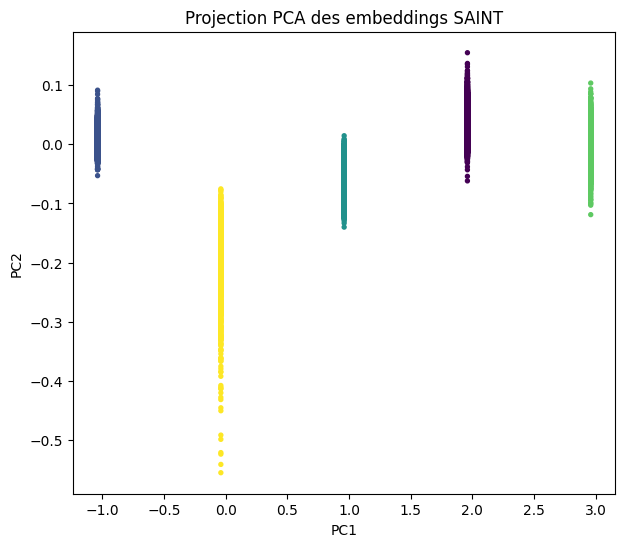

In [84]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X_vis = PCA(n_components=2, random_state=42).fit_transform(X_saint)

plt.figure(figsize=(7, 6))
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=labels_saint, s=8)
plt.title("Projection PCA des embeddings SAINT")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [85]:
meta_query = text("""
    SELECT
        p.id AS point_id,
        p.dataset_id,
        p.matrix,
        p.year,
        p.pfas_sum
    FROM public.pfas_points p
    WHERE p.category = 'Measurement'
""")

meta_df = pd.read_sql(meta_query, engine)

audit_df = embeddings_df.merge(meta_df, on="point_id", how="left")

X_saint = audit_df[[c for c in audit_df.columns if c.startswith("z")]].to_numpy(dtype=float)

from sklearn.cluster import KMeans
km = KMeans(n_clusters=5, random_state=42, n_init=10)
audit_df["cluster"] = km.fit_predict(X_saint)

print("=== Cluster x dataset_id ===")
display(pd.crosstab(audit_df["cluster"], audit_df["dataset_id"]))

print("=== Cluster x matrix ===")
display(pd.crosstab(audit_df["cluster"], audit_df["matrix"]))

print("=== Cluster x year ===")
display(pd.crosstab(audit_df["cluster"], audit_df["year"]))

=== Cluster x dataset_id ===


dataset_id,10,11,12,16,18,19,20,21,22,23,25,26,27,28
cluster,,,,,,,,,,,,,,
0,5,9,699,27170,404,244,745,1971,2229,1371,118,71,17,20721
1,0,33,15,1499,49,1,0,0,0,0,2,97,17,15
2,1,34,103,8054,188,10,45,82,88,124,13,46,24,252
3,0,1,39,7736,108,32,21,165,94,33,17,10,24,416
4,3,17,1651,7764,234,427,165,526,541,325,108,1,60,197


=== Cluster x matrix ===


matrix,Biota,Drinking water,Groundwater,Rainwater,Sea water,Sediment,Sludge,Soil,Surface water,Unknown,Wastewater
cluster,,,,,,,,,,,
0,191,46,37411,1,377,812,6,13819,2815,42,254
1,146,0,1137,0,20,5,0,237,151,3,29
2,213,7,4887,15,42,64,3,3095,696,9,33
3,117,4,2398,0,20,352,1,5492,272,6,34
4,37,33,6000,0,665,42,1,2550,2249,2,440


=== Cluster x year ===


year,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,...,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0
cluster,,,,,,,,,,,,,,,,,,,,,
0,6,24,99,27,41,77,99,889,1021,1076,...,1963,2387,3558,3406,3408,5239,9814,8871,6905,2338
1,0,0,1,1,1,4,4,0,7,17,...,8,27,1,52,27,109,304,494,611,16
2,1,2,1,17,4,26,22,13,14,31,...,47,89,241,318,311,1000,2247,2245,1890,456
3,0,1,1,2,2,14,9,8,24,25,...,109,244,117,165,280,1331,1868,2405,1505,485
4,8,28,88,85,133,255,272,116,165,89,...,302,404,388,327,308,1323,2932,2230,1403,519


In [ ]:
#  les concentrations nettoyées
pfas_clean_df = df.copy()

cluster_assign = audit_df[["point_id", "cluster"]].copy()
pfas_cluster_df = pfas_clean_df.merge(cluster_assign, on="point_id", how="inner")

cluster_means = pfas_cluster_df.groupby("cluster")[pfas_cols].mean()

display(cluster_means.iloc[:, :20])  # 20 premières colonnes
print(cluster_means.shape)

,pfas_sum,pfas_3,pfas_4,pfas_5,pfas_12,pfas_14,pfas_15,pfas_18,pfas_19,pfas_21,pfas_22,pfas_23,pfas_24,pfas_26,pfas_27,pfas_28,pfas_32,pfas_33,pfas_36,pfas_37
cluster,,,,,,,,,,,,,,,,,,,,
0,3.544843e+04,0.000018,0.000000,0.000000,0.000000,0.000011,0.000011,0.001972,0.000000,0.000000,0.000000,0.000000,0.000179,0.000000,0.000360,0.003301,0.000000,0.000000,0.000207,0.000000
1,3.560391e+06,0.000000,0.001389,0.002488,0.000026,0.000289,0.000289,0.000000,0.000000,0.000289,0.000150,0.000150,0.770833,0.733796,0.000000,6.793981,0.047627,0.047627,0.047627,5.787037
2,3.304429e+05,0.000110,0.000331,0.000000,0.000000,0.000077,0.000077,0.000000,1.257723,0.000000,0.000003,0.000003,0.036297,0.015997,0.004380,0.855693,0.001953,0.001953,0.005042,0.000000
3,2.175937e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.077047,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000069,0.000000
4,2.149493e+04,0.000000,0.000108,0.000000,0.000000,0.000067,0.000067,0.000000,0.000000,0.000033,0.000000,0.000000,0.000000,0.000000,0.004077,0.027315,0.007546,0.007546,0.011341,0.000000


(5, 290)
